# Formativa 2 — Fase 3: modelamiento predictivo de `RainTomorrow`

**Grupo 7 · Proyecto Lluvias Australia**

## Objetivo y decisiones metodológicas

Este notebook integra hallazgos de S1/S2 y prepara un clasificador para estimar `RainTomorrow`. Compara eliminación de filas, imputación simple e imputación por regresión de `Sunshine`; realiza una partición estratificada 70/30; calcula VIF; ajusta tres regresiones logísticas (variables justificadas, stepwise AIC y modelo reducido); evalúa matriz de confusión, accuracy, precisión, recall, F1, ROC-AUC y PR-AUC; y aplica bootstrap por localidad a los coeficientes del modelo seleccionado.

La clase positiva representa cerca del 22,42 % de los registros etiquetados, por lo que la exactitud no basta. Se pondera `RainTomorrow = Yes` con peso 2,2 para priorizar su detección. Un falso negativo significa no anticipar lluvia que sí ocurre; un falso positivo anticipa lluvia que no ocurre. La importancia relativa depende del uso previsto.

**Limitaciones:** el CSV ya fue explorado en S1/S2; por ello, el test no es totalmente independiente de decisiones exploratorias anteriores. La partición aleatoria estratificada mezcla fechas y localidades, así que no prueba por sí sola la generalización a años futuros. Los coeficientes expresan asociaciones, no causalidad.

## 1. Entorno y carga de datos
Se conserva intacto el CSV original. Ejecuta el notebook desde la raíz del repositorio.

In [14]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)

features_valid = [
    "Humidity3pm", "Sunshine", "Rainfall", "MaxTemp"
]

# Buscar el CSV desde la carpeta actual y sus carpetas superiores.
ruta = next(
    (
        carpeta / "data" / "raw" / "weatherAUS.csv"
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (carpeta / "data" / "raw" / "weatherAUS.csv").is_file()
    ),
    None
)

if ruta is None:
    raise FileNotFoundError("No se encontró data/raw/weatherAUS.csv")

# Conservar una versión original de los datos.
df_original = pd.read_csv(ruta, parse_dates=["Date"])

# Excluir respuestas desconocidas y codificar la clase positiva.
df = df_original.loc[
    df_original["RainTomorrow"].isin(["No", "Yes"])
].copy()

df["y"] = df["RainTomorrow"].map({"No": 0, "Yes": 1}).astype(int)

print("Archivo:", ruta)
print("SHA-256:", hashlib.sha256(ruta.read_bytes()).hexdigest())
print("Dimensión original:", df_original.shape)
print("Objetivos ausentes:", df_original["RainTomorrow"].isna().sum())
print("Filas con objetivo conocido:", len(df))
print("Predictores:", features_valid)
print("Semilla:", SEED)

display(df["RainTomorrow"].value_counts().to_frame("n"))

Archivo: C:\Users\jguai\Proyectos\UNAB\MCDI501\Proyecto-Lluvias-Australia-Grupo7\data\raw\weatherAUS.csv
SHA-256: 573fd715cd69fcacc4df32024d823b450ae3edaae7e8ff2eeb623adbed424014
Dimensión original: (145460, 23)
Objetivos ausentes: 3267
Filas con objetivo conocido: 142193
Predictores: ['Humidity3pm', 'Sunshine', 'Rainfall', 'MaxTemp']
Semilla: 42


,n
RainTomorrow,
No,110316
Yes,31877


In [2]:
import sys
import importlib
from pathlib import Path

print("Python:", sys.version.split()[0])
print("Ejecutable:", sys.executable)
print("Carpeta actual:", Path.cwd())

paquetes = [
    "numpy", "pandas", "matplotlib",
    "scipy", "sklearn", "statsmodels.api"
]

for nombre in paquetes:
    try:
        modulo = importlib.import_module(nombre)
        version = getattr(modulo, "__version__", "")
        print(f"{nombre}: OK {version}")
    except Exception as error:
        print(f"{nombre}: ERROR — {error}")

Python: 3.13.0
Ejecutable: C:\Users\jguai\AppData\Local\Programs\Python\Python313\python.exe
Carpeta actual: C:\Users\jguai\Proyectos\UNAB\MCDI501\Proyecto-Lluvias-Australia-Grupo7\notebooks
numpy: OK 2.5.3
pandas: OK 3.0.5
matplotlib: OK 3.11.2
scipy: OK 1.18.1
sklearn: OK 1.9.1
statsmodels.api: OK 0.15.0


In [3]:
%pip install scikit-learn statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Distribución de clases y faltantes

Distribución de RainTomorrow:


,Cantidad,Porcentaje (%)
RainTomorrow,,
No,110316,77.58
Yes,31877,22.42


Valores faltantes entre los registros con objetivo conocido:


,Datos observados,Datos faltantes,Faltantes (%)
Sunshine,74377,67816,47.69
Humidity3pm,138583,3610,2.54
Rainfall,140787,1406,0.99
MaxTemp,141871,322,0.23


Casos completos: 73,392
Eliminar filas incompletas descartaría 68,801 registros (48.39 %).


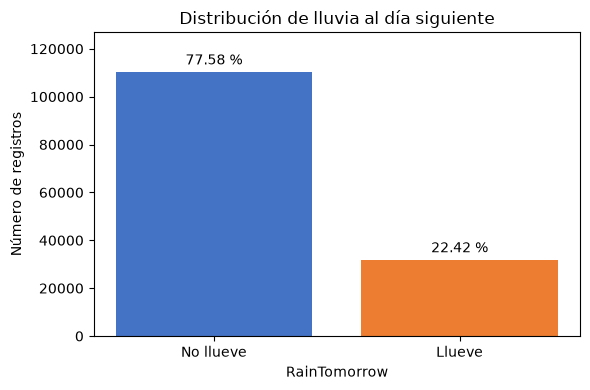

In [15]:
import matplotlib.pyplot as plt

# Distribución de la variable objetivo.
clases = (
    df["RainTomorrow"]
    .value_counts()
    .reindex(["No", "Yes"])
    .to_frame("Cantidad")
)
clases["Porcentaje (%)"] = 100 * clases["Cantidad"] / len(df)

print("Distribución de RainTomorrow:")
display(clases.round(2))

# Faltantes en los cuatro predictores seleccionados.
faltantes = pd.DataFrame({
    "Datos observados": df[features_valid].notna().sum(),
    "Datos faltantes": df[features_valid].isna().sum(),
    "Faltantes (%)": 100 * df[features_valid].isna().mean()
})

print("Valores faltantes entre los registros con objetivo conocido:")
display(
    faltantes
    .sort_values("Faltantes (%)", ascending=False)
    .round(2)
)

# Cuantificar la pérdida que produciría eliminar casos incompletos.
casos_completos = df[features_valid].notna().all(axis=1).sum()
filas_perdidas = len(df) - casos_completos

print(f"Casos completos: {casos_completos:,}")
print(
    f"Eliminar filas incompletas descartaría "
    f"{filas_perdidas:,} registros "
    f"({100 * filas_perdidas / len(df):.2f} %)."
)

# Visualización de las clases.
fig, ax = plt.subplots(figsize=(6, 4))

barras = ax.bar(
    ["No llueve", "Llueve"],
    clases["Cantidad"],
    color=["#4472C4", "#ED7D31"]
)

ax.bar_label(
    barras,
    labels=[
        f"{porcentaje:.2f} %"
        for porcentaje in clases["Porcentaje (%)"]
    ],
    padding=3
)

ax.set(
    title="Distribución de lluvia al día siguiente",
    xlabel="RainTomorrow",
    ylabel="Número de registros"
)
ax.set_ylim(0, clases["Cantidad"].max() * 1.15)

plt.tight_layout()
plt.show()

### Interpretación y tratamiento propuesto

Entre los 142.193 registros con RainTomorrow conocido, el 77,58 %
corresponde a días sin lluvia al día siguiente y el 22,42 % a días
con lluvia. Existe un desbalance de clases: predecir siempre “No”
alcanzaría una exactitud de 77,58 %, pero no detectaría ningún día
lluvioso. Por ello, evaluaremos también precision, recall, F1 y AUC.

Sunshine concentra la mayor proporción de datos faltantes (47,69 %).
Le siguen Humidity3pm (2,54 %), Rainfall (0,99 %) y MaxTemp (0,23 %).
Exigir observaciones completas en los cuatro predictores reduciría
la muestra a 73.392 registros, descartando el 48,39 % de los casos
con respuesta conocida.

Para este modelo inicial se utilizará imputación por mediana,
calculada exclusivamente con el conjunto de entrenamiento y aplicada
posteriormente al conjunto de prueba. Esta estrategia conserva los
registros y reduce la influencia de valores extremos sobre el valor
de reemplazo. Sin embargo, puede alterar las distribuciones y las
relaciones entre variables; especialmente en Sunshine, su elevada
ausencia constituye una limitación que la imputación simple no resuelve.

## 3. Selección de variables e integración de S1 y S2

Se seleccionan cuatro predictores: Humidity3pm, Sunshine, Rainfall
y MaxTemp. La elección considera las asociaciones exploratorias
del proyecto, los resultados inferenciales de S1 y la evaluación
de estabilidad mediante remuestreo de S2.

### Evidencia que respalda la selección

| Predictor | Evidencia del trabajo previo | Justificación |
|---|---|---|
| Humidity3pm | En la Formativa 1 presentó una correlación de Spearman de 0,431 con RainTomorrow, codificado como Yes = 1. En S1, la diferencia media de humedad entre días previos a lluvia y días previos a ausencia de lluvia fue de 20,08 puntos porcentuales, dando igual peso a cada localidad. En S2, su IC bootstrap del 95 % fue [18,52; 21,62]. | Se incorpora por su asociación con la respuesta y la estabilidad de la diferencia de humedad bajo remuestreo de localidades. |
| Sunshine | En la Formativa 1 presentó una correlación de −0,438 con RainTomorrow. S2 encontró una correlación de −0,620 con Humidity3pm, con IC bootstrap del 95 % [−0,660; −0,580]. | Se incorpora por su asociación con la respuesta. Su relación con la humedad requiere revisar multicolinealidad mediante VIF. La elevada proporción de faltantes limita su interpretación. |
| Rainfall | En la Formativa 1 presentó una correlación de 0,332 con RainTomorrow. En S2, su correlación con Humidity3pm fue de 0,444, con IC bootstrap del 95 % [0,411; 0,474]. | Permite evaluar la asociación entre precipitación del día y lluvia al día siguiente, ajustando por los demás predictores. La magnitud de su relación con la humedad fue sensible a la exclusión de extremos. |
| MaxTemp | En la Formativa 1 presentó una correlación de −0,159 con RainTomorrow. S2 confirmó una correlación de 0,984 con Temp3pm, con IC bootstrap del 95 % [0,981; 0,987]. | Se incorpora como variable de temperatura, con baja proporción de faltantes. Se excluye Temp3pm para evitar incluir dos mediciones fuertemente redundantes. |

Los intervalos de correlación de S2 se obtuvieron mediante 10.000
réplicas de bootstrap por localidad completa. Describen la estabilidad
de asociaciones entre predictores, no la estabilidad de sus coeficientes
logísticos ni su capacidad predictiva individual. La asociación
Humidity3pm–Sunshine se evaluó en las 30 localidades con pares
observados.

### Tratamiento de valores extremos

Se conservan los valores extremos meteorológicamente plausibles.
En S1 se identificó una marcada asimetría de Rainfall. Además, en S2,
aplicar cercas de Tukey al par Humidity3pm–Rainfall excluyó el 17,89 %
de los pares y redujo su correlación de 0,444 a 0,307.

Este análisis muestra sensibilidad al rango de precipitación; no
demuestra que los registros señalados sean errores. Por ello, no se
aplica eliminación automática ni recorte de extremos en este modelo.

### Alcance del modelo

Se ajustará una regresión logística con estos cuatro predictores.
Las correlaciones anteriores son asociaciones marginales; los
coeficientes del modelo describirán asociaciones ajustadas por las
otras variables. Sus signos y magnitudes no tienen que coincidir.

La selección utiliza información exploratoria del mismo conjunto
de datos revisado en etapas anteriores. Esta circunstancia se
considerará una limitación al interpretar el desempeño en prueba.
Las asociaciones observadas no permiten establecer causalidad.

## 4. Partición estratificada 70/30

Se divide el conjunto con RainTomorrow conocido en entrenamiento
(70 %) y prueba (30 %), utilizando estratificación por la variable
objetivo y semilla 42 para reproducir la partición.

El modelo, la imputación y la estandarización se ajustarán
exclusivamente con entrenamiento. El conjunto de prueba se
reservará para evaluar el desempeño predictivo.

Esta partición aleatoria puede distribuir registros de una misma
localidad y fechas próximas entre ambos conjuntos. Por ello, no
permite demostrar generalización a periodos futuros o a localidades
no observadas. La validación temporal y geográfica se plantea como
una mejora para la Sumativa 3.

In [16]:
from sklearn.model_selection import train_test_split

# Dividir los índices conservando la proporción de ambas clases.
train_idx, test_idx = train_test_split(
    df.index,
    test_size=0.30,
    random_state=SEED,
    stratify=df["y"]
)

train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()

# Separar predictores y respuesta.
X_train = train[features_valid].copy()
X_test = test[features_valid].copy()

y_train = train["y"].copy()
y_test = test["y"].copy()

# Comprobar que no se comparten registros y que no se pierden filas.
assert train.index.intersection(test.index).empty
assert len(train) + len(test) == len(df)

resumen_particion = pd.DataFrame({
    "Registros": [len(train), len(test)],
    "Sin lluvia": [
        int((y_train == 0).sum()),
        int((y_test == 0).sum())
    ],
    "Con lluvia": [
        int((y_train == 1).sum()),
        int((y_test == 1).sum())
    ],
    "Lluvia (%)": [
        100 * y_train.mean(),
        100 * y_test.mean()
    ]
}, index=["Entrenamiento", "Prueba"])

display(resumen_particion.round(2))

print("Semilla:", SEED)
print("Predictores:", X_train.columns.tolist())
print("Registros compartidos: 0")
print("Partición verificada. Todavía no se han imputado ni escalado datos.")

,Registros,Sin lluvia,Con lluvia,Lluvia (%)
Entrenamiento,99535,77221,22314,22.42
Prueba,42658,33095,9563,22.42


Semilla: 42
Predictores: ['Humidity3pm', 'Sunshine', 'Rainfall', 'MaxTemp']
Registros compartidos: 0
Partición verificada. Todavía no se han imputado ni escalado datos.


## 5. Imputación y estandarización

Se aplica imputación simple por mediana a los cuatro predictores.
Las medianas se calculan exclusivamente con entrenamiento y se
utilizan para reemplazar los valores faltantes de ambos conjuntos.

Después de imputar, se estandarizan los predictores restando la
media de entrenamiento y dividiendo por su desviación estándar
poblacional (ddof = 0). Los mismos parámetros se aplican a prueba.

La estandarización facilita trabajar con variables de distintas
unidades e interpretar los odds ratios por un incremento de una
desviación estándar del predictor imputado en entrenamiento.
No convierte las distribuciones en normales ni elimina valores extremos.

El conjunto de prueba no interviene en el cálculo de medianas,
medias ni desviaciones estándar.

In [17]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Imputar: aprender las medianas solamente con entrenamiento.
imputador = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputador.fit_transform(X_train),
    columns=features_valid,
    index=X_train.index
)

X_test_imp = pd.DataFrame(
    imputador.transform(X_test),
    columns=features_valid,
    index=X_test.index
)

# Estandarizar: aprender media y desviación solo con entrenamiento.
escalador = StandardScaler()

X_train_scaled = pd.DataFrame(
    escalador.fit_transform(X_train_imp),
    columns=features_valid,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    escalador.transform(X_test_imp),
    columns=features_valid,
    index=X_test.index
)

# Documentar los parámetros utilizados.
resumen_preprocesamiento = pd.DataFrame({
    "Faltantes train": X_train.isna().sum(),
    "Faltantes test": X_test.isna().sum(),
    "Mediana train": imputador.statistics_,
    "Media tras imputar (train)": escalador.mean_,
    "DE tras imputar (train)": escalador.scale_
}, index=features_valid)

display(resumen_preprocesamiento.round(3))

# Comprobar que los datos preparados no contienen NaN ni infinitos.
assert np.isfinite(X_train_scaled.to_numpy()).all()
assert np.isfinite(X_test_scaled.to_numpy()).all()

print("Dimensión entrenamiento:", X_train_scaled.shape)
print("Dimensión prueba:", X_test_scaled.shape)
print("Datos preparados sin valores faltantes ni infinitos.")

,Faltantes train,Faltantes test,Mediana train,Media tras imputar (train),DE tras imputar (train)
Humidity3pm,2536,1074,52.0,51.496,20.554
Sunshine,47607,20209,8.5,8.043,2.768
Rainfall,966,440,0.0,2.326,8.448
MaxTemp,218,104,22.6,23.227,7.120


Dimensión entrenamiento: (99535, 4)
Dimensión prueba: (42658, 4)
Datos preparados sin valores faltantes ni infinitos.


## 6. Diagnóstico de multicolinealidad mediante VIF

Se calcula el factor de inflación de la varianza (VIF) para los
cuatro predictores, utilizando los datos de entrenamiento imputados
y estandarizados. Las regresiones auxiliares incluyen intercepto,
aunque no se presenta el VIF de la constante.

El VIF evalúa la redundancia lineal de cada predictor respecto
de los restantes. Se utiliza un valor superior a 5 como señal
orientativa para revisar posibles problemas, no como una regla
automática de eliminación.

Este diagnóstico corresponde a los datos después de imputar.
Un VIF bajo no demuestra independencia entre predictores ni
entre observaciones, y tampoco garantiza buen desempeño predictivo.

In [18]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# Matriz de entrenamiento con intercepto.
# También se utilizará para ajustar la regresión logística.
X_train_model = sm.add_constant(
    X_train_scaled,
    has_constant="add"
).astype(float)

# Calcular el VIF de cada predictor incluyendo el intercepto
# en todas las regresiones auxiliares.
matriz_vif = X_train_model.to_numpy()

vif_tabla = pd.DataFrame([
    {
        "Predictor": nombre,
        "VIF": variance_inflation_factor(matriz_vif, posicion)
    }
    for posicion, nombre in enumerate(X_train_model.columns)
    if nombre != "const"
])

display(
    vif_tabla
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
    .round(3)
)

print("Registros utilizados:", len(X_train_model))
print("Diagnóstico calculado exclusivamente con entrenamiento.")

,Predictor,VIF
0,Humidity3pm,1.569
1,MaxTemp,1.364
2,Sunshine,1.257
3,Rainfall,1.076


Registros utilizados: 99535
Diagnóstico calculado exclusivamente con entrenamiento.


Los VIF obtenidos fueron 1,569 para Humidity3pm, 1,364 para MaxTemp,
1,257 para Sunshine y 1,076 para Rainfall. Todos se encuentran por
debajo del umbral orientativo de 5, por lo que este diagnóstico no
justifica eliminar predictores por multicolinealidad. Se mantienen
las cuatro variables seleccionadas. Estos resultados corresponden
al conjunto de entrenamiento después de la imputación.

## 7. Modelo de regresión logística

Se ajusta una regresión logística para estimar la probabilidad
de lluvia al día siguiente, utilizando Humidity3pm, Sunshine,
Rainfall y MaxTemp. La respuesta se codifica como Yes = 1 y No = 0.

El ajuste se realiza mediante máxima verosimilitud, con intercepto,
sin regularización ni ponderación de clases, utilizando únicamente
los 99.535 registros de entrenamiento.

Los coeficientes describen cambios en el logaritmo de las odds
de lluvia, manteniendo constantes los demás predictores.
Al estar estandarizadas las variables, cada coeficiente corresponde
a un incremento de una desviación estándar del predictor imputado
en entrenamiento.

Los errores estándar, intervalos y valores p del ajuste son
convencionales: no incorporan la dependencia temporal o geográfica
identificada previamente. Su interpretación inferencial será
exploratoria y no causal.

In [19]:
# Comprobar que cada fila de predictores coincide con su respuesta.
assert X_train_model.index.equals(y_train.index)

# Ajustar un único modelo logístico con los cuatro predictores.
modelo_logit = sm.Logit(
    endog=y_train,
    exog=X_train_model
)

resultado_logit = modelo_logit.fit(
    method="newton",
    maxiter=100,
    tol=1e-10,
    disp=False
)

# Mostrar el resumen y comprobar la convergencia.
print(resultado_logit.summary())

print(
    "\nConvergencia alcanzada:",
    resultado_logit.mle_retvals["converged"]
)
print(
    "Observaciones utilizadas:",
    int(resultado_logit.nobs)
)

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                99535
Model:                          Logit   Df Residuals:                    99530
Method:                           MLE   Df Model:                            4
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.2344
Time:                        14:41:59   Log-Likelihood:                -40553.
converged:                       True   LL-Null:                       -52968.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -1.6518      0.010   -158.768      0.000      -1.672      -1.631
Humidity3pm     1.1677      0.012     97.224      0.000       1.144       1.191
Sunshine       -0.4128      0.009    -45.973    

In [20]:
# Intervalos convencionales del 95 % para los coeficientes.
intervalos_coef = resultado_logit.conf_int(alpha=0.05)

# Convertir coeficientes e intervalos a la escala de odds ratios.
tabla_coeficientes = pd.DataFrame({
    "Coeficiente": resultado_logit.params,
    "Error estándar": resultado_logit.bse,
    "Odds ratio": np.exp(resultado_logit.params),
    "IC 95 % OR inferior": np.exp(intervalos_coef.iloc[:, 0]),
    "IC 95 % OR superior": np.exp(intervalos_coef.iloc[:, 1]),
    "Valor p": resultado_logit.pvalues
}).rename_axis("Término")

# Dar formato únicamente a la presentación.
# La tabla conserva sus valores numéricos para exportarlos después.
display(
    tabla_coeficientes.style.format({
        "Coeficiente": "{:.4f}",
        "Error estándar": "{:.4f}",
        "Odds ratio": "{:.3f}",
        "IC 95 % OR inferior": "{:.3f}",
        "IC 95 % OR superior": "{:.3f}",
        "Valor p": lambda p: "<0,001" if p < 0.001 else f"{p:.3f}"
    })
)

,Coeficiente,Error estándar,Odds ratio,IC 95 % OR inferior,IC 95 % OR superior,Valor p
Término,,,,,,
const,-1.6518,0.0104,0.192,0.188,0.196,"<0,001"
Humidity3pm,1.1677,0.0120,3.215,3.140,3.291,"<0,001"
Sunshine,-0.4128,0.0090,0.662,0.650,0.674,"<0,001"
Rainfall,0.3091,0.0106,1.362,1.334,1.391,"<0,001"
MaxTemp,0.1917,0.0103,1.211,1.187,1.236,"<0,001"


### 7.1. Interpretación de los coeficientes y odds ratios

Las interpretaciones siguientes mantienen constantes los otros
tres predictores. Cada incremento corresponde a una desviación
estándar calculada después de imputar el conjunto de entrenamiento.

- **Humidity3pm:** el coeficiente es 1,1677 y el OR es 3,215
  (IC 95 %: 3,140–3,291). Un incremento de aproximadamente
  20,55 puntos porcentuales de humedad se asocia con multiplicar
  las odds de lluvia por 3,215. No significa multiplicar la
  probabilidad por ese mismo valor.

- **Sunshine:** el coeficiente es −0,4128 y el OR es 0,662
  (IC 95 %: 0,650–0,674). Un incremento de aproximadamente
  2,77 horas de sol se asocia con odds de lluvia un 33,8 % menores.
  La interpretación está limitada por la elevada imputación
  de esta variable.

- **Rainfall:** el coeficiente es 0,3091 y el OR es 1,362
  (IC 95 %: 1,334–1,391). Un incremento de aproximadamente
  8,45 mm de precipitación se asocia con odds de lluvia al día
  siguiente un 36,2 % mayores.

- **MaxTemp:** el coeficiente es 0,1917 y el OR es 1,211
  (IC 95 %: 1,187–1,236). Un incremento de aproximadamente
  7,12 °C se asocia con odds de lluvia un 21,1 % mayores.

El signo positivo de MaxTemp en este modelo no se interpreta
igual que su correlación marginal negativa con RainTomorrow
observada anteriormente. Aquí se estima una asociación ajustada
por humedad, horas de sol y precipitación, sobre datos imputados.

El intercepto de −1,6518 representa el logaritmo de las odds
estimadas cuando los cuatro predictores estandarizados valen cero,
es decir, cuando se encuentran en sus medias de entrenamiento
después de la imputación.

Los cuatro predictores presentan p < 0,001 e intervalos de OR que
no incluyen 1 bajo los supuestos del ajuste convencional.
La dependencia temporal y geográfica puede afectar esta inferencia.
La significancia estadística no demuestra causalidad ni garantiza
utilidad predictiva.

El pseudo-R² de McFadden es 0,2344. Compara la log-verosimilitud
del modelo ajustado con la del modelo que contiene solo intercepto;
no representa un porcentaje de varianza explicada ni la exactitud.
El desempeño predictivo se evaluará en el conjunto de prueba.

## 8. Evaluación en test: matriz de confusión, métricas y curvas

El umbral 0,50 se utiliza como referencia común; no se optimiza sobre test. En la fase siguiente, el umbral operativo debe elegirse mediante validación dentro del conjunto de entrenamiento, de acuerdo con el equilibrio deseado entre recall y precisión.

,n_test,n_test_comun,accuracy,precision_yes,recall_yes,f1_yes,roc_auc,pr_auc
modelo,,,,,,,,
A · Variables justificadas,42658,42658,0.7960,0.5393,0.6184,0.5761,0.8258,0.6264
B · Stepwise AIC,42658,42658,0.8105,0.5689,0.6388,0.6018,0.8477,0.6577
C · Reducido,42658,42658,0.7979,0.5452,0.5945,0.5688,0.8039,0.6099


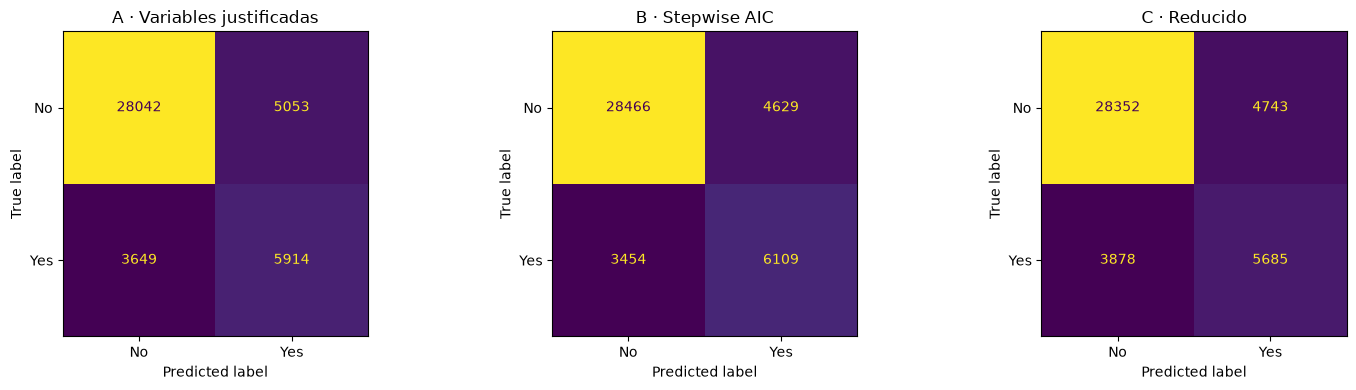

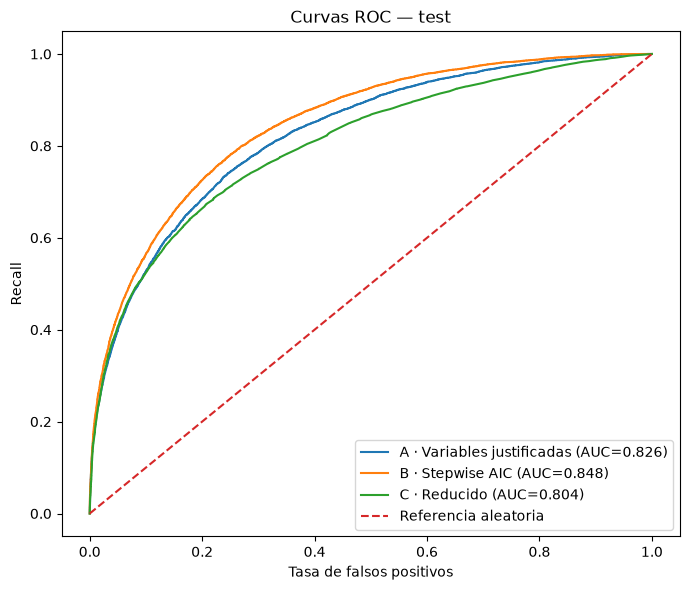

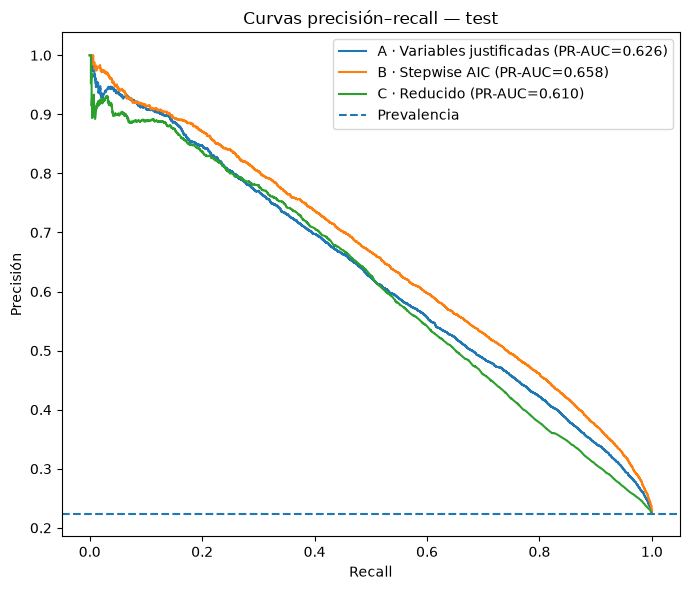

In [10]:
def predict_sm(model, data, features):
    X, _ = sm_data(data, features)
    return np.asarray(model.predict(X))

probs_test, preds_test, rows = {}, {}, []
for name, features in specs.items():
    p = predict_sm(models[name], test_reg, features)
    pred = (p >= 0.5).astype(int)
    probs_test[name], preds_test[name] = p, pred
    rows.append({"modelo": name, "n_test": len(test_reg), **metricas(test_reg.y, p)})
metricas_test = pd.DataFrame(rows).set_index("modelo")
display(metricas_test.round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, _) in zip(axes, specs.items()):
    cm = confusion_matrix(test_reg.y, preds_test[name], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, p in probs_test.items():
    fpr, tpr, _ = roc_curve(test_reg.y, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(test_reg.y, p):.3f})")
ax.plot([0, 1], [0, 1], "--", label="Referencia aleatoria")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Recall", title="Curvas ROC — test")
ax.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for name, p in probs_test.items():
    prec, rec, _ = precision_recall_curve(test_reg.y, p)
    ax.plot(rec, prec, label=f"{name} (PR-AUC={average_precision_score(test_reg.y, p):.3f})")
ax.axhline(test_reg.y.mean(), linestyle="--", label="Prevalencia")
ax.set(xlabel="Recall", ylabel="Precisión", title="Curvas precisión–recall — test")
ax.legend(); plt.tight_layout(); plt.show()

## 9. Bootstrap por localidad del modelo con menor AIC de entrenamiento

La selección del modelo para bootstrap se basa en el AIC no ponderado calculado solo con entrenamiento, no en el test. En cada réplica se remuestrean localidades con reemplazo y se conservan sus registros de entrenamiento. Esto reconoce parcialmente el agrupamiento espacial, pero no resuelve la dependencia temporal dentro de cada localidad. La proporción de réplicas que mantienen un signo describe estabilidad empírica, no una probabilidad de que una hipótesis sea verdadera.

Modelo para bootstrap: B · Stepwise AIC | variables: ['Humidity3pm', 'RainToday', 'Pressure3pm', 'Sunshine', 'Rainfall', 'MaxTemp']


,variable,n_replicas,media,mediana,ic95_inf,ic95_sup,proporcion_positivo,proporcion_signo_mayoritario
0,Humidity3pm,100,0.0394,0.0393,0.0354,0.0431,1.00,1.00
1,MaxTemp,100,0.0107,0.0105,-0.0074,0.0302,0.83,0.83
2,Pressure3pm,100,-0.0960,-0.0962,-0.1131,-0.0801,0.00,1.00
3,RainToday,100,0.5126,0.5163,0.4053,0.6124,1.00,1.00
4,Rainfall,100,0.0119,0.0116,0.0085,0.0162,1.00,1.00
5,Sunshine,100,-0.2009,-0.2012,-0.2182,-0.1800,0.00,1.00
6,const,100,95.5865,95.7472,79.3502,113.3838,1.00,1.00


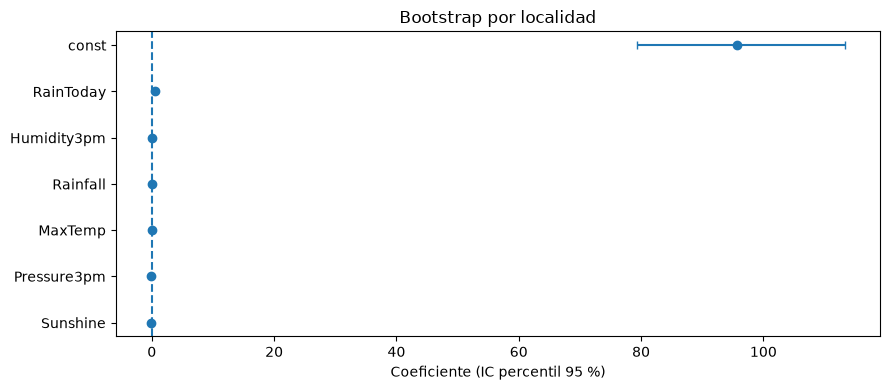

In [11]:
aic_train = {name: fit_aic(train_reg, vars_).aic for name, vars_ in specs.items()}
best_name = min(aic_train, key=aic_train.get)
best_features = specs[best_name]
print("Modelo para bootstrap:", best_name, "| variables:", best_features)

N_BOOTSTRAP = 100  # Para el informe final, aumentar a 300+ si el tiempo lo permite.
rng = np.random.default_rng(SEED)
locs = train_reg["Location"].dropna().unique()
groups = {loc: train_reg[train_reg.Location == loc].copy() for loc in locs}
boot_rows = []
for b in range(N_BOOTSTRAP):
    sampled = rng.choice(locs, size=len(locs), replace=True)
    boot = pd.concat([groups[loc] for loc in sampled], ignore_index=True)
    try:
        fitted = fit_weighted(boot, best_features)
        for var, val in fitted.params.items():
            boot_rows.append({"replica": b, "variable": var, "coeficiente": float(val)})
    except Exception:
        continue

boot_df = pd.DataFrame(boot_rows)
if boot_df.empty:
    raise RuntimeError("No se completaron réplicas bootstrap.")
boot_summary = boot_df.groupby("variable").coeficiente.agg(
    n_replicas="count", media="mean", mediana="median",
    ic95_inf=lambda x: x.quantile(.025), ic95_sup=lambda x: x.quantile(.975),
    proporcion_positivo=lambda x: (x > 0).mean()
).reset_index()
boot_summary["proporcion_signo_mayoritario"] = np.maximum(
    boot_summary.proporcion_positivo, 1 - boot_summary.proporcion_positivo
)
display(boot_summary.round(4))

plot = boot_summary.sort_values("mediana").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, max(4, .45*len(plot))))
ypos = np.arange(len(plot))
ax.errorbar(plot.mediana, ypos,
            xerr=[plot.mediana - plot.ic95_inf, plot.ic95_sup - plot.mediana],
            fmt="o", capsize=3)
ax.axvline(0, linestyle="--")
ax.set_yticks(ypos); ax.set_yticklabels(plot.variable)
ax.set_xlabel("Coeficiente (IC percentil 95 %)"); ax.set_title("Bootstrap por localidad")
plt.tight_layout(); plt.show()

## 10. Síntesis final (máximo una página)

La siguiente síntesis se genera con los resultados de la ejecución. Revísala antes de entregar: agrega interpretación sustantiva y no declares superior un modelo solo por accuracy.

In [12]:
best_auc = metricas_test["roc_auc"].idxmax()
best_recall = metricas_test["recall_yes"].idxmax()
n_boot_ok = int(boot_df.replica.nunique())
sintesis = f'''
### Síntesis de resultados

Se ajustaron tres regresiones logísticas para `RainTomorrow`, utilizando una partición estratificada de 70 % entrenamiento y 30 % prueba. La clase positiva representa {df.y.mean():.2%} de los registros etiquetados, por lo que la exactitud debe complementarse con recall, precisión, F1, ROC-AUC y PR-AUC.

La comparación de faltantes se evaluó sobre una cohorte común de {len(test_complete):,} casos completos de prueba. La eliminación reduce los datos disponibles para entrenar; la imputación simple es transparente y conserva observaciones; la imputación por regresión estima `Sunshine` a partir de variables meteorológicas y localidad. Dado el alto porcentaje de faltantes de `Sunshine`, y que no se ha demostrado un mecanismo MCAR/MAR, las estimaciones imputadas deben interpretarse con cautela.

El mayor ROC-AUC en test correspondió a **{best_auc}** ({metricas_test.loc[best_auc, "roc_auc"]:.3f}); el mayor recall para `Yes` correspondió a **{best_recall}** ({metricas_test.loc[best_recall, "recall_yes"]:.3f}). La ponderación 2,2 prioriza la detección de lluvia, pero el umbral definitivo debe definirse con validación en entrenamiento y según el costo relativo de falsos positivos y falsos negativos.

El bootstrap por localidad completó {n_boot_ok} réplicas. La estabilidad se interpreta mediante los intervalos y la proporción de réplicas que mantienen el signo de cada coeficiente. Los resultados no demuestran causalidad y pueden verse afectados por dependencia temporal, diferencias entre localidades y exploración previa del conjunto completo.

Para S3 se recomienda validar el umbral sin usar test, probar una partición temporal (entrenar con años anteriores y evaluar años posteriores), documentar los costos de error y aumentar las réplicas bootstrap si el tiempo computacional lo permite.
'''
display(Markdown(sintesis))


### Síntesis de resultados

Se ajustaron tres regresiones logísticas para `RainTomorrow`, utilizando una partición estratificada de 70 % entrenamiento y 30 % prueba. La clase positiva representa 22.42% de los registros etiquetados, por lo que la exactitud debe complementarse con recall, precisión, F1, ROC-AUC y PR-AUC.

La comparación de faltantes se evaluó sobre una cohorte común de 21,929 casos completos de prueba. La eliminación reduce los datos disponibles para entrenar; la imputación simple es transparente y conserva observaciones; la imputación por regresión estima `Sunshine` a partir de variables meteorológicas y localidad. Dado el alto porcentaje de faltantes de `Sunshine`, y que no se ha demostrado un mecanismo MCAR/MAR, las estimaciones imputadas deben interpretarse con cautela.

El mayor ROC-AUC en test correspondió a **B · Stepwise AIC** (0.848); el mayor recall para `Yes` correspondió a **B · Stepwise AIC** (0.639). La ponderación 2,2 prioriza la detección de lluvia, pero el umbral definitivo debe definirse con validación en entrenamiento y según el costo relativo de falsos positivos y falsos negativos.

El bootstrap por localidad completó 100 réplicas. La estabilidad se interpreta mediante los intervalos y la proporción de réplicas que mantienen el signo de cada coeficiente. Los resultados no demuestran causalidad y pueden verse afectados por dependencia temporal, diferencias entre localidades y exploración previa del conjunto completo.

Para S3 se recomienda validar el umbral sin usar test, probar una partición temporal (entrenar con años anteriores y evaluar años posteriores), documentar los costos de error y aumentar las réplicas bootstrap si el tiempo computacional lo permite.


## 11. Exportación de resultados
Se escriben salidas nuevas en `results/04_formativa2/`; no se modifican los archivos originales ni los resultados de S1/S2.

In [13]:
out = Path("results/04_formativa2")
out.mkdir(parents=True, exist_ok=True)
comparacion_imputacion.to_csv(out / "comparacion_imputacion.csv")
vif.to_csv(out / "vif_predictores.csv", index=False)
aic_table.to_csv(out / "comparacion_modelos_aic.csv", index=False)
coeficientes.to_csv(out / "coeficientes_modelos.csv")
metricas_test.to_csv(out / "metricas_test.csv")
boot_summary.to_csv(out / "bootstrap_coeficientes.csv", index=False)
with open(out / "resumen_modelamiento.json", "w", encoding="utf-8") as f:
    json.dump({
        "semilla": SEED, "train": 0.70, "test": 0.30, "estratificada": True,
        "prevalencia_yes": float(df.y.mean()), "modelo_bootstrap": best_name,
        "variables_bootstrap": best_features, "bootstrap_solicitadas": N_BOOTSTRAP,
        "bootstrap_completadas": n_boot_ok
    }, f, ensure_ascii=False, indent=2)
print("Resultados guardados en:", out.resolve())
print(sorted(p.name for p in out.iterdir()))

Resultados guardados en: C:\Users\jguai\Proyectos\UNAB\MCDI501\Proyecto-Lluvias-Australia-Grupo7\notebooks\results\04_formativa2
['bootstrap_coeficientes.csv', 'coeficientes_modelos.csv', 'comparacion_imputacion.csv', 'comparacion_modelos_aic.csv', 'metricas_test.csv', 'resumen_modelamiento.json', 'vif_predictores.csv']
